In [1]:
# Logistic Regression - Titanic Dataset

import pandas as pd


In [2]:

df = pd.read_csv("titanic.csv")
print(df.head())

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN        S  


In [3]:

# Data Preprocessing
print("Missing values:\n", df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())


Missing values:
 PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64
Duplicate rows: 0


In [4]:

df = df.drop_duplicates()

In [5]:
# Select useful columns
df = df[["Survived", "Pclass", "Sex", "Age",
         "SibSp", "Parch", "Fare", "Embarked"]].copy()

In [6]:

# Fill missing values
df["Age"] = df["Age"].fillna(df["Age"].median())
df["Fare"] = df["Fare"].fillna(df["Fare"].median())
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

In [7]:
# Encode categorical columns
df = pd.get_dummies(df, columns=["Sex", "Embarked"], dtype=int)

In [8]:


# Split features and target
X = df.drop("Survived", axis=1)
y = df["Survived"]

In [9]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

In [10]:

# Model Training
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [11]:
# Model Evaluation
from sklearn.metrics import accuracy_score, classification_report

y_pred = log_reg.predict(X_test)

print("\nLogistic Regression Results")
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))



Logistic Regression Results
Accuracy: 0.7985074626865671
              precision    recall  f1-score   support

           0       0.83      0.84      0.84       165
           1       0.74      0.73      0.74       103

    accuracy                           0.80       268
   macro avg       0.79      0.79      0.79       268
weighted avg       0.80      0.80      0.80       268



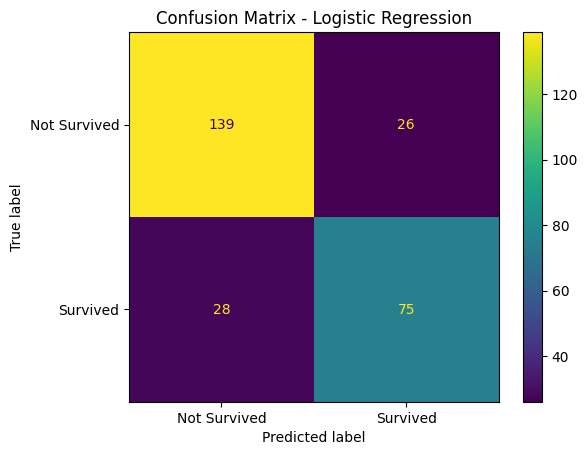

In [12]:
# Confusion Matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["Not Survived", "Survived"]
)
plt.title("Confusion Matrix - Logistic Regression")
plt.show()


In [13]:

# External Prediction
new_data = pd.DataFrame([{
    "Pclass": 3,
    "Sex": "male",
    "Age": 25,
    "SibSp": 0,
    "Parch": 0,
    "Fare": 8.05,
    "Embarked": "S"
}])

# Apply the same encoding
new_data = pd.get_dummies(
    new_data, columns=["Sex", "Embarked"], dtype=int
)
new_data = new_data.reindex(columns=X.columns, fill_value=0)

result = log_reg.predict(new_data)[0]

print("Prediction:", "Survived" if result == 1 else "Not Survived")


Prediction: Not Survived
